----
# Wprowadzenie - część 1
----
Materiały dydaktyczne przeznaczone są wyłącznie dla studentów wydziału Informatyki i Telekomunikacji Politechniki Poznańskiej  

## 0. Zagadnienia do opanowania przed zajęciami
### 0.1. Zapoznanie z podstawami językiem programowania *Python*
https://www.w3schools.com/python/python_intro.asp  
### 0.2. Zapoznanie z postawami biblioteki *numpy*
https://www.w3schools.com/python/numpy_intro.asp  
https://numpy.org/devdocs/user/quickstart.html  
### 0.3. Zapoznanie z postawami biblioteki *sympy*
https://docs.sympy.org/latest/tutorial/index.html
### 0.4. Przydatne informacje:
Funkcje z biblioteki *numpy* potrzebne do zrealizowania ćwiczenia:  
`numpy.linspace, numpy.sin, numpy.min, numpy.max, numpy.random.uniform, numpy.random.normal, numpy.poly1d, numpy.polymul, numpy.polyder, numpy.polyval`  
Dokumentacja i opisy poszczególnych funkcji *numpy*:  
https://numpy.org/doc/stable/reference/    

Funkcje z biblioteki *matplotlib* potrzebne do zrealizowania ćwiczenia:  
`matplotlib.pyplot.figure, matplotlib.pyplot.plot, matplotlib.pyplot.title, matplotlib.pyplot.xlabel, matplotlib.pyplot.ylabel, matplotlib.pyplot.grid, atplotlib.pyplot.axis, matplotlib.pyplot.subplot`  
Dokumentacja i opisy poszczególnych funkcji *matplotlib*:  
https://matplotlib.org/3.3.1/api/_as_gen/matplotlib.pyplot.html#module-matplotlib.pyplot




## 🧭 Jak czytać ten notatnik
Każde zadanie ma ten sam układ:
1. **Treść zadania** – oryginalna komórka prowadzącego,
2. **📘 Teoria** – co liczymy i dlaczego,
3. **🔧 Składnia** – opis funkcji użytych w kodzie (co robią, jakie przyjmują argumenty, co zwracają),
4. **Kod** – z komentarzem przy każdej linijce,
5. **💡 Wyjaśnienie wyniku / ✅ Wnioski**.

Na końcu notatnika jest **📝 ściąga** z najważniejszymi funkcjami.

### 🔧 Składnia – użyte funkcje

- `%matplotlib inline` – polecenie Jupytera (nie Pythona!): wykresy pojawiają się bezpośrednio pod komórką.
- `import numpy as np` – wczytuje bibliotekę **numpy** (obliczenia na wektorach/macierzach) i nadaje jej skrót `np`. Od teraz piszemy `np.sin(...)` zamiast `numpy.sin(...)`.
- `import matplotlib.pyplot as plt` – moduł do rysowania wykresów, skrót `plt`.
- `default_figsize=(14, 8)` – zwykła zmienna: krotka (szerokość, wysokość) okna wykresu w calach. Używamy jej potem w `plt.figure(figsize=default_figsize)`.

In [1]:
%matplotlib inline
import numpy as np                 # numpy – obliczenia numeryczne na wektorach
import matplotlib.pyplot as plt    # pyplot – rysowanie wykresów
import sympy                       # sympy – obliczenia symboliczne (potrzebne w zadaniu 4)
default_figsize = (14, 8)          # domyślny rozmiar okna wykresu (szer., wys.) w calach

----
## 1. Rysowanie wykresów
----
### Zadanie: Narysuj wykres jednego okresu funkcji $f(\omega) = sin(\omega + \frac{\pi}{4})$
* zmień kolor wykresu
* dodaj opisy osi i tytuł wykresu
* zastosuj 10% marginesy

### 📘 Teoria

Funkcja $f(\omega)=\sin\left(\omega+\frac{\pi}{4}\right)$ to zwykły sinus **przesunięty w lewo o $\frac{\pi}{4}$** (przesunięcie fazowe).

- Okres sinusa to $2\pi$, więc **jeden okres** to np. przedział $\omega \in [0,\ 2\pi]$.
- W $\omega=0$ funkcja ma wartość $\sin\frac{\pi}{4}=\frac{\sqrt2}{2}\approx0{,}707$ (a nie 0 jak zwykły sinus).
- Maksimum $1$ wypada w $\omega=\frac{\pi}{4}$, bo wtedy argument sinusa to $\frac{\pi}{2}$.

**Jak komputer rysuje funkcję?** Nie rysuje „ciągłej” krzywej – liczy wartości w wielu punktach (próbkach) i łączy je odcinkami. Dlatego najpierw tworzymy wektor argumentów (np. 500 punktów od 0 do $2\pi$), potem wektor wartości, a dopiero potem `plt.plot(x, y)`.

**Marginesy 10%** – domyślnie matplotlib dosuwa oś prawie do samego wykresu. Margines 10% oznacza, że wokół danych zostaje wolne miejsce równe 10% ich zakresu (np. zakres y to $[-1,1]$ o szerokości 2 → po 0,2 wolnego miejsca u góry i u dołu).

### 🔧 Składnia – użyte funkcje

| Funkcja | Co robi | Przykład |
|---|---|---|
| `np.linspace(start, stop, n)` | zwraca wektor **n** równo rozłożonych liczb od `start` do `stop` (oba końce włącznie) | `np.linspace(0, 1, 5)` → `[0, 0.25, 0.5, 0.75, 1]` |
| `np.sin(x)` | sinus **każdego elementu** wektora `x` (kąt w radianach) | `np.sin(np.array([0, np.pi/2]))` → `[0, 1]` |
| `np.pi` | stała $\pi$ | |
| `plt.figure(figsize=(szer, wys))` | otwiera nowe okno wykresu o podanym rozmiarze | |
| `plt.plot(x, y, kolor)` | rysuje linię przez punkty `(x[i], y[i])`; trzeci argument to format, np. `'r'` czerwony, `'g--'` zielony przerywany, `'bo'` niebieskie kropki | `plt.plot(x, y, 'r')` |
| `plt.plot(..., color='purple')` | kolor można też podać nazwą lub kodem `'#ff8800'` | |
| `plt.title('tekst')`, `plt.xlabel(...)`, `plt.ylabel(...)` | tytuł i opisy osi | |
| `plt.margins(0.1)` | margines 10% wokół danych (0.1 = 10%) | |
| `plt.grid()` | siatka | |
| `plt.show()` | wyświetla gotowy wykres | |

`def nazwa():` – definicja własnej funkcji w Pythonie. Ciało funkcji musi być **wcięte** (4 spacje). `return` kończy funkcję. Wywołanie: `nazwa()`.

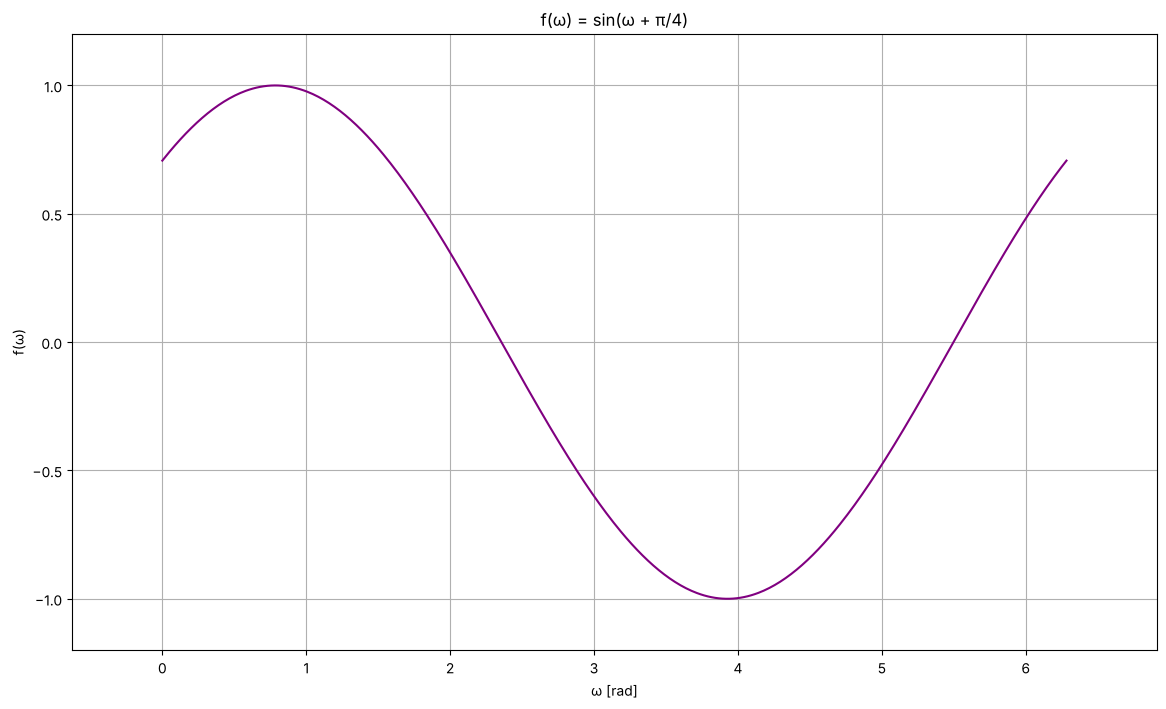

In [2]:
def introduction_plot_sinus():
    #narysuj wykres
    w = np.linspace(0, 2*np.pi, 500)       # 500 argumentów ω od 0 do 2π – dokładnie jeden okres
    f = np.sin(w + np.pi/4)                # wartość funkcji w każdym punkcie: sin(ω + π/4)

    plt.figure(figsize=default_figsize)    # nowe okno wykresu o domyślnym rozmiarze
    plt.plot(w, f, color='purple')         # linia przez punkty (ω, f) – kolor zmieniony na fioletowy
    #dodaj opisy osi i tytuł wykresu
    plt.title('f(ω) = sin(ω + π/4)')       # tytuł wykresu
    plt.xlabel('ω [rad]')                  # opis osi poziomej
    plt.ylabel('f(ω)')                     # opis osi pionowej
    #zastosować 10% marginesy
    plt.margins(0.1)                       # 10% wolnego miejsca wokół danych na obu osiach
    plt.grid()                             # siatka ułatwiająca odczyt wartości
    plt.show()                             # wyświetlenie wykresu
    return                                 # koniec funkcji (nic nie zwraca)

introduction_plot_sinus()                  # wywołanie funkcji – dopiero teraz rysuje się wykres

### 💡 Wyjaśnienie wyniku

- Wykres zaczyna się w $\approx0{,}707$, a nie w zerze – to efekt przesunięcia o $\frac{\pi}{4}$.
- Maksimum jest w $\omega=\frac{\pi}{4}\approx0{,}785$, minimum w $\omega=\frac{5\pi}{4}\approx3{,}93$.
- Dzięki `plt.margins(0.1)` oś y sięga od ok. $-1{,}2$ do $1{,}2$, a nie dokładnie od $-1$ do $1$.

----
## 2. Podział okna wykresu
----
### Zadanie: Używając „subplot” narysuj wykres 3 funkcji w następujący sposób:
(dla x w zakresie $<-0,2\pi>$)
<table>
  <tr>
    <td colspan="2" bgcolor="blue" width="200" height="100" style="color: white; text-align:center">sin(x)</td>
  </tr>
  <tr>
    <td bgcolor="red" width="100" height="100" style="color: white; text-align:center">cos(x)</td>
    <td bgcolor="green" width="100" height="100" style="color: white; text-align:center">arctan(x)</td>
  </tr>
</table>

### 📘 Teoria

Trzy funkcje w przedziale $x\in[0,\ 2\pi]$:
- $\sin x$ – okresowa, wartości od $-1$ do $1$,
- $\cos x$ – to samo co sinus, ale przesunięta o $\frac{\pi}{2}$ (zaczyna się od 1),
- $\arctan x$ – **funkcja odwrotna do tangensa**: rosnąca, nieokresowa, wartości zawsze w przedziale $\left(-\frac{\pi}{2},\ \frac{\pi}{2}\right)$; dla dużych $x$ zbliża się do $\frac{\pi}{2}\approx1{,}57$.

**Podział okna** – górny wykres ma zajmować całą szerokość, a dolne po połowie. Sztuczka: okno można dzielić **różnie dla różnych wykresów**:
- górny wykres rysujemy w siatce **2 wiersze × 1 kolumna**, pole nr 1 (cały górny wiersz),
- dolne w siatce **2 × 2**, pola nr 3 i 4 (lewy i prawy dół).

### 🔧 Składnia – użyte funkcje

**`plt.subplot(wiersze, kolumny, numer)`** – dzieli okno na siatkę i wybiera pole, w którym będą rysowane kolejne polecenia (`plot`, `title`, …). Pola numerujemy **od 1, wierszami** (od lewej do prawej, potem kolejny wiersz):

```
siatka 2×2:          siatka 2×1:
┌───┬───┐            ┌───────┐
│ 1 │ 2 │            │   1   │
├───┼───┤            ├───────┤
│ 3 │ 4 │            │   2   │
└───┴───┘            └───────┘
```
Dlatego `subplot(2,1,1)` = cały górny wiersz, a `subplot(2,2,3)` i `subplot(2,2,4)` = dolne ćwiartki.

- `np.cos(x)`, `np.arctan(x)` – cosinus i arcus tangens każdego elementu wektora.
- `plt.plot(x, y, 'b')` – `'b'` blue, `'r'` red, `'g'` green (kolory jak w tabelce z zadania).
- `plt.tight_layout()` – automatycznie rozsuwa wykresy, żeby tytuły i opisy osi na siebie nie nachodziły.

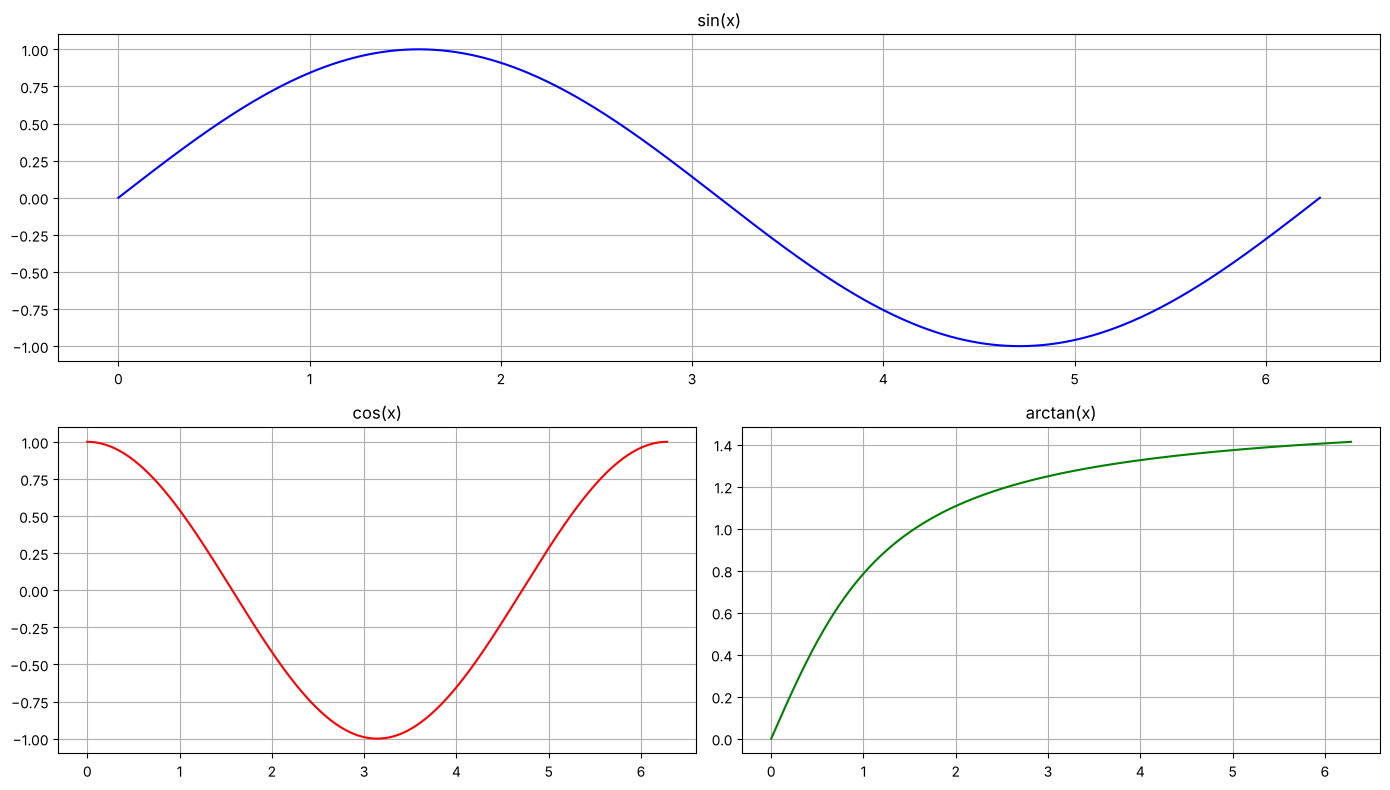

In [3]:
def introduction_plot_subplot():
    #narysuj wykres
    x = np.linspace(0, 2*np.pi, 500)       # 500 punktów x od 0 do 2π

    plt.figure(figsize=default_figsize)    # nowe okno wykresu

    plt.subplot(2, 1, 1)                   # siatka 2×1, pole 1 → cały górny wiersz
    plt.plot(x, np.sin(x), 'b')            # sin(x) na niebiesko
    plt.title('sin(x)')                    # tytuł tego pola
    plt.grid()                             # siatka

    plt.subplot(2, 2, 3)                   # siatka 2×2, pole 3 → lewy dolny róg
    plt.plot(x, np.cos(x), 'r')            # cos(x) na czerwono
    plt.title('cos(x)')
    plt.grid()

    plt.subplot(2, 2, 4)                   # siatka 2×2, pole 4 → prawy dolny róg
    plt.plot(x, np.arctan(x), 'g')         # arctan(x) na zielono
    plt.title('arctan(x)')
    plt.grid()

    plt.tight_layout()                     # rozsunięcie wykresów, żeby się nie nakładały
    plt.show()                             # wyświetlenie całego okna
    return

introduction_plot_subplot()

### 💡 Wyjaśnienie wyniku

- Górny wykres zajmuje całą szerokość, dolne po połowie – dokładnie jak w tabelce z treści.
- $\arctan x$ rośnie od 0 i „wypłaszcza się” – przy $x=2\pi$ ma wartość $\approx1{,}41$, coraz bliżej $\frac{\pi}{2}\approx1{,}57$, ale nigdy jej nie osiąga.

---- 
## 3. Operacje na wielomianach
---- 
### Dla zdefiniowanych wielomianów:  
$ a(x) = x^4 + x^3 - x^2 - 1 $  
$ b(x) = x^3 - x + 1 $  
$ c(x) = x^5 - x^4 + x^3 - 1 $  
### Wylicz:  
$ d(x) = a(x) \cdot c(x)$  
$ e(x) = \frac{\partial d(x)}{\partial x}$  
$ f(x) = e(x) + b(x) - x^{3}$  
### Narysuj wykres wielomianu $f(x)$ dla $x\in<-1,1>$


### 📘 Teoria

**Wielomian jako wektor współczynników.** W numpy wielomian zapisujemy jako listę współczynników **od najwyższej potęgi**, wpisując **0 dla brakujących potęg**:

$$a(x)=x^4+x^3-x^2+0\cdot x-1 \;\Rightarrow\; [1,\ 1,\ -1,\ 0,\ -1]$$
$$b(x)=x^3+0\cdot x^2-x+1 \;\Rightarrow\; [1,\ 0,\ -1,\ 1]$$
$$c(x)=x^5-x^4+x^3+0\cdot x^2+0\cdot x-1 \;\Rightarrow\; [1,\ -1,\ 1,\ 0,\ 0,\ -1]$$

**Operacje:**
- **Mnożenie** $d=a\cdot c$ – każdy wyraz razy każdy (stopnie się dodają: $4+5=9$).
- **Pochodna** $e=d'$ – każdy wyraz $a_n x^n$ przechodzi w $n\,a_n x^{n-1}$ (stopień spada o 1, czyli do 8).
- **Suma** $f=e+b-x^3$ – dodajemy współczynniki przy tych samych potęgach. $x^3$ to wielomian $[1,0,0,0]$.

Wynik (sprawdzony niżej w kodzie):
$$d(x)=x^9 - x^7 + 2x^6 - 2x^5 - 2x^3 + x^2 + 1$$
$$e(x)=d'(x)=9x^8 - 7x^6 + 12x^5 - 10x^4 - 6x^2 + 2x$$
$$f(x)=9x^8 - 7x^6 + 12x^5 - 10x^4 - 6x^2 + x + 1$$

### 🔧 Składnia – użyte funkcje

| Funkcja | Co robi | Przykład |
|---|---|---|
| `np.poly1d([współczynniki])` | tworzy **obiekt wielomianu**. Można go wyświetlić (`print`), dodawać `+`, odejmować `-`, mnożyć `*` i **wywołać jak funkcję**: `p(2)` liczy wartość w $x=2$ | `p = np.poly1d([1, 0, -1])` → $x^2-1$ |
| `np.polymul(a, b)` | iloczyn dwóch wielomianów | `np.polymul([1,1],[1,-1])` → $x^2-1$ |
| `np.polyder(p)` | pochodna wielomianu (opcjonalnie `np.polyder(p, 2)` = druga pochodna) | `np.polyder([1,0,0])` → $2x$ |
| `np.polyval(p, x)` | wartość wielomianu w punkcie / dla całego wektora `x` (to samo co `p(x)`) | `np.polyval([1,0,-1], 3)` → `8` |
| `print(p)` | ładnie wypisuje wielomian (potęgi są w linijce **nad** wyrazem) | |
| `p.coeffs` | sam wektor współczynników | |
| `np.min(y)`, `np.max(y)` | najmniejsza / największa wartość wektora | |

a(x) =
    4     3     2
1 x + 1 x - 1 x - 1 

b(x) =
    3
1 x - 1 x + 1 

c(x) =
    5     4     3
1 x - 1 x + 1 x - 1 

d(x) = a·c =
    9     7     6     5     3     2
1 x - 1 x + 2 x - 2 x - 2 x + 1 x + 1 

e(x) = d'(x) =
    8     6      5      4     2
9 x - 7 x + 12 x - 10 x - 6 x + 2 x 

f(x) = e + b - x^3 =
    8     6      5      4     2
9 x - 7 x + 12 x - 10 x - 6 x + 1 x + 1


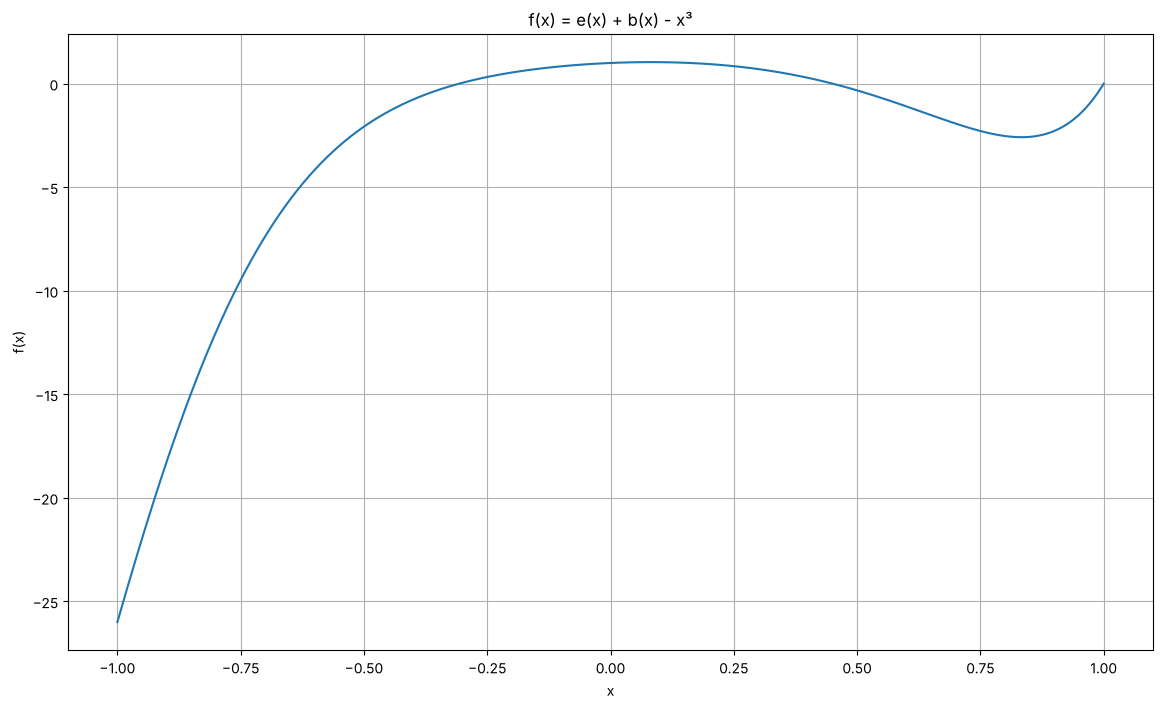

In [4]:
def introduction_plot_polynomial():
    #wykonaj operacje na wielomianach
    # --- definicja wielomianów (współczynniki od najwyższej potęgi, 0 = brak potęgi) ---
    a = np.poly1d([1, 1, -1, 0, -1])          # a(x) = x^4 + x^3 - x^2 - 1
    b = np.poly1d([1, 0, -1, 1])              # b(x) = x^3 - x + 1
    c = np.poly1d([1, -1, 1, 0, 0, -1])       # c(x) = x^5 - x^4 + x^3 - 1
    x3 = np.poly1d([1, 0, 0, 0])              # pomocniczy wielomian x^3

    # --- operacje na wielomianach ---
    d = np.polymul(a, c)                      # d(x) = a(x) · c(x)
    e = np.polyder(d)                         # e(x) = d'(x) – pochodna
    f = e + b - x3                            # f(x) = e(x) + b(x) - x^3 (poly1d obsługuje + i -)

    #wyświetl wielomiany
    print('a(x) =\n', a, '\n')                # '\n' = nowa linia
    print('b(x) =\n', b, '\n')
    print('c(x) =\n', c, '\n')
    print('d(x) = a·c =\n', d, '\n')
    print("e(x) = d'(x) =\n", e, '\n')        # cudzysłów " bo w tekście jest apostrof '
    print('f(x) = e + b - x^3 =\n', f)

    #narysuj wykres – f(x) dla x z przedziału <-1, 1>
    x = np.linspace(-1, 1, 500)               # 500 punktów od -1 do 1
    y = np.polyval(f, x)                      # wartości f(x) w tych punktach (to samo co f(x))

    plt.figure(figsize=default_figsize)       # nowe okno
    plt.plot(x, y)                            # wykres f(x)
    plt.title('f(x) = e(x) + b(x) - x³')      # tytuł
    plt.xlabel('x')                           # opis osi x
    plt.ylabel('f(x)')                        # opis osi y
    plt.grid()                                # siatka
    plt.show()                                # wyświetlenie
    return

introduction_plot_polynomial()

### 💡 Wyjaśnienie wyniku

- `print` wyświetla wielomian w dwóch linijkach: **górna linijka to wykładniki potęg**, dolna to wyrazy. Np.
```
   2
3 x - 1
```
oznacza $3x^2-1$.
- $d$ ma stopień $4+5=9$, $e$ ma stopień 8, $f$ też 8 (dodanie $b$ i odjęcie $x^3$ nie zmienia najwyższej potęgi).
- $e$ nie ma wyrazu z $x^3$ (w $d$ nie było $x^4$). $b$ dokłada $x^3$, a my odejmujemy $x^3$, więc w $f$ potęgi trzeciej nie ma w ogóle. Z $b$ zostaje $-x+1$, więc $2x$ z $e$ zmienia się w $x$ i pojawia się wyraz wolny $1$.
- Sprawdzenie: $f(0)=1$ (wyraz wolny), $f(1)=9-7+12-10-6+1+1=0$ – zgadza się z wykresem.

---- 
## 4. Sympy - moduł obliczeń symbolicznych
---- 
Funkcje z biblioteki sympy potrzebne do zrealizowania ćwiczenia:  
* deklaracja zmienej symbolicznej `t = sympy.Symbol('t')`, opcjonalnie z dodatkowymi atrybutami np. `t = sympy.Symbol('t', real=True)`.  
* wyznaczanie całki nieoznaczonej  $\int x^2 dx$ `sympy.integrate(x**2, x)`  
* wyznaczanie całki oznaczonej $\int_{a}^{b} x^2 dx$ `sympy.integrate(x**2, (x, a, b))`  
* wyświetlanie sformatowanego wyniku `display(  )`  
  
Wyznacz $\int t^2 dt$ oraz $\int_{-1}^{1} t^2 dt$ i wyświetl wyniki.

### 📘 Teoria

**Obliczenia numeryczne vs symboliczne:**
- **numpy** liczy na **liczbach** – wynik to np. `0.6666667`.
- **sympy** liczy na **symbolach** jak człowiek na kartce – wynik to dokładny wzór, np. $\frac{t^3}{3}$ albo $\frac{2}{3}$.

**Całki:**
- nieoznaczona: $\int t^2\,dt=\frac{t^3}{3}+C$ (sympy **pomija stałą $C$**),
- oznaczona: $\int_{-1}^{1} t^2\,dt=\left[\frac{t^3}{3}\right]_{-1}^{1}=\frac{1}{3}-\left(-\frac{1}{3}\right)=\frac{2}{3}$.

### 🔧 Składnia – użyte funkcje

| Funkcja | Co robi |
|---|---|
| `t = sympy.Symbol('t')` | tworzy **symbol** `t` – „literkę”, którą sympy traktuje jak niewiadomą w matematyce. Tekst `'t'` to nazwa wyświetlana, zmienna Pythona `t` to obiekt, którym liczymy |
| `sympy.Symbol('t', real=True)` | to samo, ale z założeniem, że `t` jest liczbą rzeczywistą (sympy lepiej upraszcza) |
| `t**2` | potęga w Pythonie to `**`, **nie** `^` |
| `sympy.integrate(wyrażenie, t)` | całka nieoznaczona po `t` |
| `sympy.integrate(wyrażenie, (t, a, b))` | całka oznaczona od `a` do `b` – granice podajemy w **krotce** `(zmienna, od, do)` |
| `display(...)` | (Jupyter) ładnie wyświetla wzór w formie matematycznej, zamiast tekstu jak `print` |
| `sympy.Integral(...)` | sama całka „niepoliczona” – przydaje się do wyświetlenia, *co* liczymy (`display(sympy.Eq(sympy.Integral(...), wynik))`) |
| `sympy.Eq(lewa, prawa)` | równanie `lewa = prawa`, tylko do ładnego wyświetlenia |

In [5]:
def introduction_symbolic():
    #zadeklaruj zmienną t
    t = sympy.Symbol('t', real=True)                     # zmienna symboliczna t (rzeczywista)

    #wyznacz i wyświetl całkę nieoznaczoną
    nieoznaczona = sympy.integrate(t**2, t)              # ∫ t² dt  → t³/3
    #wyznacz i wyświetl całkę oznaczoną
    oznaczona = sympy.integrate(t**2, (t, -1, 1))        # ∫_{-1}^{1} t² dt → 2/3

    display(sympy.Eq(sympy.Integral(t**2, t), nieoznaczona))            # wyświetla: ∫t²dt = t³/3
    display(sympy.Eq(sympy.Integral(t**2, (t, -1, 1)), oznaczona))      # wyświetla: ∫₋₁¹ t²dt = 2/3
    print('wartość liczbowa całki oznaczonej:', float(oznaczona))       # 0.666...
    return

introduction_symbolic()

Eq(Integral(t**2, t), t**3/3)

Eq(Integral(t**2, (t, -1, 1)), 2/3)

wartość liczbowa całki oznaczonej: 0.6666666666666666


### 💡 Wyjaśnienie wyniku

- Wynik całki nieoznaczonej to $\frac{t^3}{3}$ – **bez** stałej $+C$ (tak działa sympy).
- Całka oznaczona daje **dokładny ułamek** $\frac{2}{3}$, a nie przybliżenie. `float(...)` zamienia go na liczbę dziesiętną.
- Geometrycznie $\frac{2}{3}$ to pole pod parabolą $t^2$ między $-1$ a $1$.

----
## 5. Rozkłady statystyczne (zadanie dodatkowe)
----
### Zadanie: Wygeneruj wektor 100 000 elementów i wykreśl histogram składający się z 50 przedziałów
* wartości o rozkładzie równomiernym <-1; 1> 
* wartości o rozkładzie normalnym µ=0, σ=0.5

### 📘 Teoria

**Rozkład równomierny** $U(-1,1)$ – każda liczba z przedziału $[-1,1)$ jest **tak samo prawdopodobna**. Histogram jest „płaski” (prostokąt).

**Rozkład normalny (Gaussa)** $N(\mu, \sigma)$ – wartości skupiają się wokół średniej $\mu$, im dalej, tym rzadziej. Histogram ma kształt dzwonu. $\sigma$ (odchylenie standardowe) mówi, jak szeroki jest dzwon:
- ok. 68% wartości leży w $[\mu-\sigma,\ \mu+\sigma]$ – tu $[-0{,}5;\ 0{,}5]$,
- ok. 95% w $[\mu-2\sigma,\ \mu+2\sigma]$ – tu $[-1;\ 1]$.

**Histogram** – dzielimy zakres wartości na przedziały (tu 50) i liczymy, ile próbek wpadło do każdego. Wysokość słupka = liczba próbek w przedziale.

### 🔧 Składnia – użyte funkcje

| Funkcja | Co robi |
|---|---|
| `np.random.uniform(low, high, size)` | `size` losowych liczb z rozkładu równomiernego na $[low, high)$ |
| `np.random.normal(loc, scale, size)` | `size` liczb z rozkładu normalnego; `loc` = $\mu$ (średnia), `scale` = $\sigma$ (odchylenie) |
| `plt.hist(dane, bins=50)` | rysuje histogram z 50 przedziałami |
| `np.mean(x)`, `np.std(x)` | średnia i odchylenie standardowe wektora – do sprawdzenia, czy losowanie wyszło zgodnie z założeniami |

równomierny: min = -0.9999988383828704  max = 0.999962362201072
normalny:    średnia = 0.0002261041900014743  σ = 0.4992101880159424


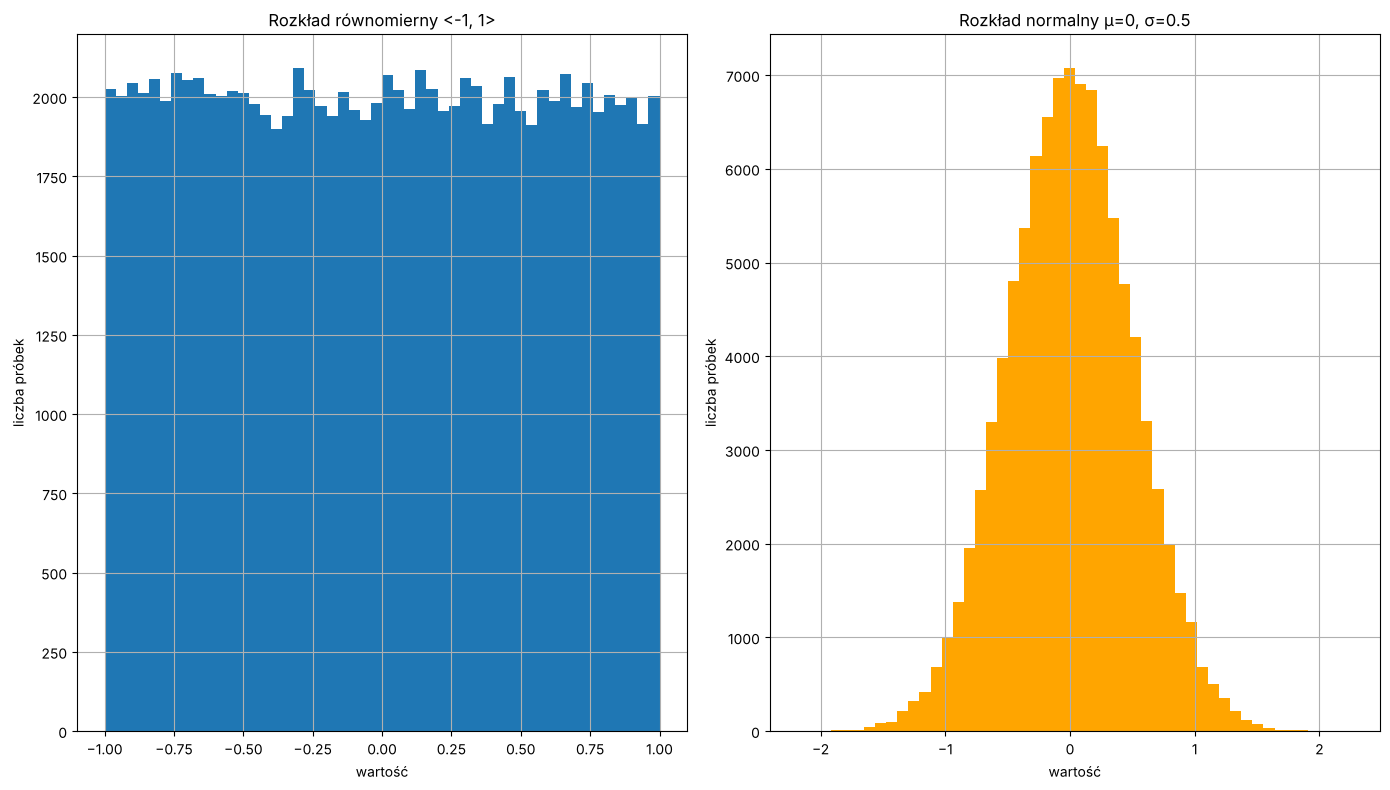

In [6]:
def introduction_plot_histogram():
    N = 100000                                          # liczba próbek

    #wygeneruj wektory elementów
    rownomierny = np.random.uniform(-1, 1, N)           # 100 000 liczb z rozkładu równomiernego na <-1, 1)
    normalny = np.random.normal(0, 0.5, N)              # 100 000 liczb z rozkładu normalnego μ=0, σ=0.5

    print('równomierny: min =', np.min(rownomierny), ' max =', np.max(rownomierny))   # powinno być ≈ -1 i ≈ 1
    print('normalny:    średnia =', np.mean(normalny), ' σ =', np.std(normalny))      # powinno być ≈ 0 i ≈ 0.5

    #narysuj histogramy
    plt.figure(figsize=default_figsize)                 # nowe okno

    plt.subplot(1, 2, 1)                                # lewa połowa
    plt.hist(rownomierny, bins=50)                      # histogram z 50 przedziałami
    plt.title('Rozkład równomierny <-1, 1>')
    plt.xlabel('wartość')
    plt.ylabel('liczba próbek')
    plt.grid()

    plt.subplot(1, 2, 2)                                # prawa połowa
    plt.hist(normalny, bins=50, color='orange')         # histogram rozkładu normalnego
    plt.title('Rozkład normalny μ=0, σ=0.5')
    plt.xlabel('wartość')
    plt.ylabel('liczba próbek')
    plt.grid()

    plt.tight_layout()
    plt.show()
    return

introduction_plot_histogram()

### 💡 Wyjaśnienie wyniku

- **Równomierny:** wszystkie 50 słupków ma podobną wysokość ≈ $\frac{100\,000}{50}=2000$ (małe różnice to losowość).
- **Normalny:** dzwon wycentrowany w 0; prawie wszystkie wartości mieszczą się w $[-1{,}5;\ 1{,}5]$ (to $\pm3\sigma$ – ok. 99,7% próbek).
- Wyniki są **losowe** – po każdym uruchomieniu histogramy będą minimalnie inne. Żeby były zawsze takie same, można na początku ustawić `np.random.seed(0)`.

---- 
## 6. THE END
---- 

---
# 🎓 Kolokwium – przykładowe pytania z rozwiązaniami
Pytania oznaczone **[z kolokwium]** to prawdziwe przykłady od prowadzącego, pozostałe są **wymyślone w tym samym stylu**. Przy każdym:
- **Odpowiedź (do wpisania)** – krótki tekst, który można wpisać w pole odpowiedzi,
- **Jak to rozwiązać** – kroki, żeby umieć zrobić podobne zadanie samemu,
- kod tam, gdzie zadanie wymaga obliczeń lub wykresu (na kolokwium można dołączyć zrzut wykresu jako obrazek).

### Pytanie 1
Dla wielomianów $p(x)=x^2-1$ i $q(x)=x+2$ wyznacz $r(x)=\dfrac{d}{dx}\big(p(x)\cdot q(x)\big)$ i narysuj $r(x)$ dla $x\in\langle-3,3\rangle$.

**Jak to rozwiązać:**
1. Zapisz wielomiany jako współczynniki od najwyższej potęgi: $p$ → `[1, 0, -1]`, $q$ → `[1, 2]`.
2. Iloczyn: `np.polymul`, pochodna: `np.polyder`.
3. Wykres: `np.linspace` + `np.polyval` + `plt.plot`.

**Odpowiedź (do wpisania):** $p\cdot q=x^3+2x^2-x-2$, $\ r(x)=3x^2+4x-1$ (parabola z minimum w $x=-\frac23$).

p·q =
    3     2
1 x + 2 x - 1 x - 2
r =
    2
3 x + 4 x - 1


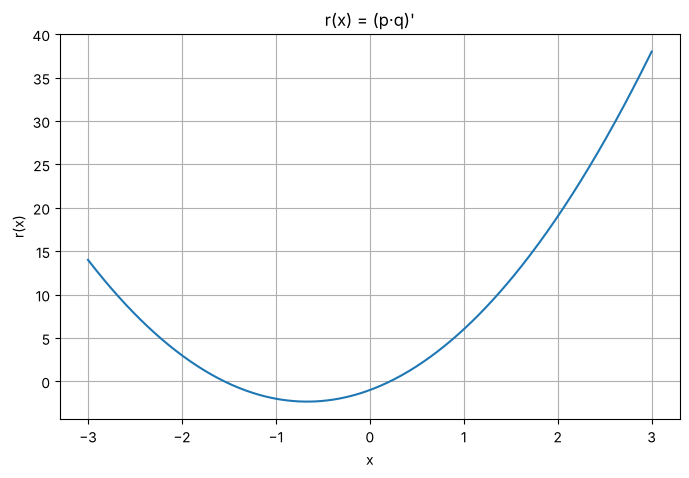

In [7]:
p = np.poly1d([1, 0, -1])                 # p(x) = x² - 1
q = np.poly1d([1, 2])                     # q(x) = x + 2
pq = np.polymul(p, q)                     # p·q
r = np.polyder(pq)                        # pochodna
print('p·q =\n', pq)
print('r =\n', r)

x = np.linspace(-3, 3, 400)               # zakres <-3, 3>
plt.figure(figsize=(8, 5))
plt.plot(x, np.polyval(r, x))             # wykres r(x)
plt.title("r(x) = (p·q)'")
plt.xlabel('x')
plt.ylabel('r(x)')
plt.grid()
plt.show()

### Pytanie 2
Wyznacz symbolicznie $\int_0^{\pi}\sin t\,dt$ oraz $\int t\,e^{t}\,dt$.

**Jak to rozwiązać:** `t = sympy.Symbol('t')`, całka oznaczona `sympy.integrate(f, (t, a, b))`, nieoznaczona `sympy.integrate(f, t)`.

**Odpowiedź (do wpisania):** $\int_0^\pi\sin t\,dt=[-\cos t]_0^\pi=1-(-1)=2$; $\ \int te^t\,dt=(t-1)e^t$ (+C; przez części).

In [8]:
t = sympy.Symbol('t', real=True)
display(sympy.integrate(sympy.sin(t), (t, 0, sympy.pi)))    # 2
display(sympy.integrate(t*sympy.exp(t), t))                 # (t - 1)·e^t

2

(t - 1)*exp(t)

### Pytanie 3 (teoria)
Czym różni się obliczenie numeryczne (numpy) od symbolicznego (sympy)?

**Odpowiedź (do wpisania):** numpy liczy na konkretnych liczbach zmiennoprzecinkowych – wynik jest przybliżony (np. `0.6666667`) i dotyczy konkretnych wartości. sympy operuje na symbolach jak człowiek na kartce – wynikiem jest dokładny wzór lub ułamek (np. $\frac{t^3}{3}$, $\frac23$), który można dalej przekształcać; `sympy.lambdify` zamienia taki wzór na funkcję numeryczną.

### Pytanie 4
Wygeneruj 10 000 próbek z rozkładu normalnego $\mu=2$, $\sigma=1$ i narysuj histogram (30 przedziałów). Ile procent próbek powinno leżeć w przedziale $[1, 3]$?

**Odpowiedź (do wpisania):** ok. **68%** – to przedział $[\mu-\sigma,\ \mu+\sigma]$ (reguła 68–95–99,7).

udział w [1, 3]: 0.6803


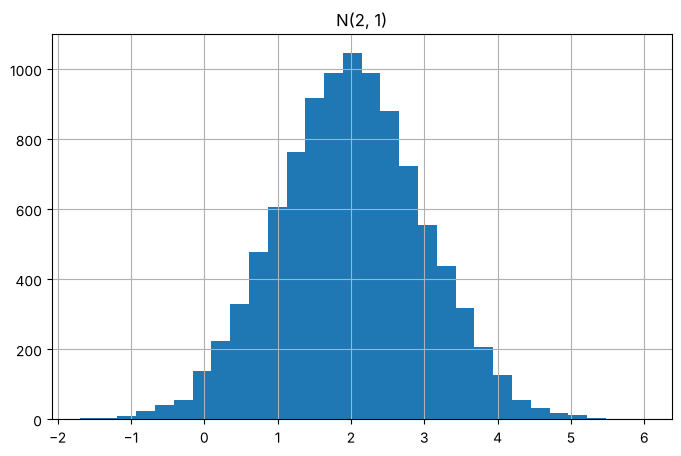

In [9]:
x = np.random.normal(2, 1, 10000)                          # μ = 2, σ = 1
print('udział w [1, 3]:', np.mean((x >= 1) & (x <= 3)))    # średnia z True/False = ułamek próbek
plt.figure(figsize=(8, 5))
plt.hist(x, bins=30)
plt.title('N(2, 1)')
plt.grid()
plt.show()

---
## 📝 Ściąga – Laboratorium 1

**numpy**
| | |
|---|---|
| `np.linspace(a, b, n)` | n punktów od a do b |
| `np.sin, np.cos, np.arctan, np.pi` | funkcje i stałe działające na całych wektorach |
| `np.min(x), np.max(x), np.mean(x), np.std(x)` | min, max, średnia, odchylenie |
| `np.random.uniform(a, b, n)` | n liczb równomiernych z $[a,b)$ |
| `np.random.normal(μ, σ, n)` | n liczb z rozkładu normalnego |
| `np.poly1d([..])` | wielomian (współczynniki od najwyższej potęgi, 0 dla brakujących) |
| `np.polymul, np.polyder, np.polyval` | iloczyn, pochodna, wartość wielomianu |

**matplotlib (`plt`)**
| | |
|---|---|
| `plt.figure(figsize=(w,h))` | nowe okno |
| `plt.subplot(wiersze, kolumny, nr)` | wybór pola w siatce (numeracja od 1, wierszami) |
| `plt.plot(x, y, 'r--')` | linia; format: kolor + styl (`-`, `--`, `o`, `x`) |
| `plt.hist(x, bins=50)` | histogram |
| `plt.title, plt.xlabel, plt.ylabel` | opisy |
| `plt.margins(0.1)` | margines 10% |
| `plt.grid(), plt.tight_layout(), plt.show()` | siatka, rozsunięcie, wyświetlenie |

**sympy**
| | |
|---|---|
| `t = sympy.Symbol('t', real=True)` | zmienna symboliczna |
| `sympy.integrate(f, t)` | całka nieoznaczona |
| `sympy.integrate(f, (t, a, b))` | całka oznaczona |
| `display(wyrażenie)` | ładne wyświetlenie wzoru |

**Python:** potęga to `**` (nie `^`), funkcja `def nazwa():` + wcięcie, `print(...)` wypisuje tekst.